In [516]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Import library

In [517]:
import pandas as pd
import numpy as np
import regex as re
import networkx as nx
import itertools as it
import matplotlib.pyplot as plt
import pickle
import os
from sentence_transformers import SentenceTransformer, util
import torch
import seaborn as sns 
import nltk
from sklearn.decomposition import PCA
from kmeans_pytorch import kmeans


# Read data


In [518]:
# parent_dir = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
# os.chdir(parent_dir)
# # Print directory 
# print(os.getcwd())

# Set the new directory
new_dir = "/Users/gl665/PycharmProjects/Phrame-MentalMaps"

# Change the current working directory
os.chdir(new_dir)

# Print the current working directory
print(os.getcwd())

/Users/gl665/PycharmProjects/Phrame-MentalMaps


In [519]:

my_data = {}
folder_path = 'Output/Overcome/'
for filename in os.listdir(folder_path):
    if filename.endswith('.json'):
        file_path = os.path.join(folder_path, filename)
        with open(file_path, 'rb') as f:
            print("load:",filename)
            data = pickle.load(f)
            # store the loaded data in a dictionary for further processing, the key is the file name, the dictionary is data
            my_data[filename] = data
                        
        

load: Overcome SF3 - 5- 10 - 2023.json
load: Overcome RC4 6-7-2023.json
load: SF2-4-28-2023.json
load: SF1-4-26-2023 revised.json
load: SF5-5-18-2023.json
load: Overcome RC1 4-5-2023.json
load: overcome RC2 4-5-2023.json
load: Ocome SF3 -5 10 23 revised.json
load: Overcome 5 6-7-2023.json
load: SF1-4-26-2023.json
load: Overcome SF4 - 5 - 10 - 2023.json
load: overcome RC3 5-5-2023.json


for renaming overcome datat: overcome_file_rename.pkl


In [520]:
with open('Output/Overcome/overcome_file_rename.pkl', 'rb') as file:
    rc_rename_files = pickle.load(file)

print(rc_rename_files)

{'Overcome RC4 6-7-2023.json': 'RC4', 'Overcome RC1 4-5-2023.json': 'RC1', 'overcome RC2 4-5-2023.json': 'RC2', 'Overcome 5 6-7-2023.json': 'RC5', 'overcome RC3 5-5-2023.json': 'RC3', 'Overcome SF3 - 5- 10 - 2023.json': 'SF3', 'SF2-4-28-2023.json': 'SF2', 'SF1-4-26-2023 revised.json': 'SF1', 'SF5-5-18-2023.json': 'SF5', 'Ocome SF3 -5 10 23 revised.json': 'SF3', 'SF1-4-26-2023.json': 'SF1', 'Overcome SF4 - 5 - 10 - 2023.json': 'SF4'}


In [521]:
# # Write pickle file
# with open('overcome_file_rename.pkl', 'wb') as file:
#     pickle.dump(overcome_file_rename, file)


In [522]:

my_data = {rc_rename_files.get(key, key): value for key, value in my_data.items()}

my_data.keys()

# create dataframe, the column is the file name and the sentence. 
df = pd.DataFrame({"file_name": my_data.keys(), "sentence": my_data.values()})

df['group'] = np.where(df['file_name'].str.contains('RC', case=False), 'RC', 'SF')
df 

,file_name,sentence,group
0,SF3,"[{'1': 'Stimulant Use', '2': 'Fatal Overdose',...",SF
1,RC4,"[{'1': 'fatal overdose', '2': 'stimulant use',...",RC
2,SF2,"[{'1': 'Stimulant Use', '2': 'Fatal Overdose',...",SF
3,SF1,"[{'1': 'Stimulant Use', '2': 'Fatal Overdose',...",SF
4,SF5,"[{'1': 'stimulant use', '2': 'fatal overdose',...",SF
5,RC1,"[{'1': 'Fatal Overdoses', '2': 'Stimulant Use'...",RC
6,RC2,"[{'1': 'Stimulant Use', '2': 'Fatal Overdose',...",RC
7,RC5,"[{'1': 'stimulant use', '2': 'fatal overdose',...",RC
8,SF4,"[{'1': 'Stimulant Use', '2': 'Fatal Overdose',...",SF
9,RC3,"[{'1': 'Stimulant Use', '2': 'Fatal overdose',...",RC


In [523]:
string_list = []

for i in my_data: 
    string_list.append(', '.join(list(my_data[i][0].values())))
    
# print(string_list[:1])
print("Number of paragraphs (CLd)s :", len(string_list))

Number of paragraphs (CLd)s : 10


# Term Frequency Inverse Document Frequency (TFIDF). 
Step 1. The TF-IDF is applied to the preprocessed data to transform it into an integer form so that clustering algorithms can use it. 

TFIdf way to measure how unique a certain word is relative to every other word in a document. This is calculated on a scale from 0–1 with the most common words approaching 0 and the most unique words approaching 1. 

In [524]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(string_list)
arr = X.toarray()

In [525]:
# from sklearn.metrics.pairwise import cosine_similarity
# 
# def create_heatmap(similarity, cmap = "YlGnBu"):
#   df = pd.DataFrame(similarity)
#   mask = np.tril(np.ones(df.shape, dtype=bool))
# 
#   df.columns = df_cld['dataset']
#   df.index = df_cld['dataset']
#   fig, ax = plt.subplots(figsize=(5,5))
#   sns.heatmap(df, cmap=cmap, annot=True, ax=ax, mask = mask)

In [526]:
# from kmeans_pytorch import kmeans
# from sklearn.decomposition import PCA
# from kmeans_pytorch import kmeans
# from sklearn.cluster import KMeans

# Perform K-Means Clustering on the Embedded Data

### functions 

In [527]:
def detect_clusters(X, nclusters, tol=1e-6):
    # Convert input data to PyTorch tensor
    X = torch.as_tensor(X, dtype=torch.float32)
    assert X.ndim == 2

    # Apply PCA to reduce dimensionality
    pca = PCA(n_components=2)
    X1 = torch.from_numpy(pca.fit_transform(X.numpy()))

    # Run kmeans on the PCA-transformed data with Euclidean distance
    cluster_ID, C = kmeans(X1, nclusters, distance='euclidean', tol=tol)
    return cluster_ID, C


In [550]:
from matplotlib.lines import Line2D

def cluster_visualization(X, group_labels, centers, cluster_labels, ax):

    # Define a dictionary mapping labels to markers
    group_dict = {
        'RC': 'o',  # Circle marker for RC
        'SF': '^'   # Triangle marker for SF
    }

    # Plot points based on their group label with different markers and colors based on cluster labels
    for group, marker in group_dict.items():
        for cluster in np.unique(cluster_labels):
            group_points = X[(group_labels == group) & (cluster_labels == cluster)]
            plt.scatter(group_points[:, 0], group_points[:, 1], marker=marker, color=f'C{cluster}', label=f'Cluster {cluster + 1}')

    # # Reference circle
    # theta = torch.linspace(0, 2 * np.pi, 1000)
    # ax.plot(torch.cos(theta), torch.sin(theta), '--k')

    # Plot cluster centers
    # ax.scatter(centers[:, 0], centers[:, 1], c='red', s=100, label='Centers')
    xlim = plt.xlim()
    ylim = plt.ylim()
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    # Draw lines from the origin to the centroids
    # R = 20
    # for c in centers:
    #     ax.plot([0, c[0] * R], [0, c[1] * R], linestyle='-', color='gray')
    # 
    # # Annotate the cluster centers with text labels
    # for i, c in enumerate(centers):
    #     ax.text(c[0], c[1], f"Cluster {i + 1}", ha='center', va='center')

    # Custom legend for markers
    marker_handles = [Line2D([0], [0], marker=marker, color='w', markerfacecolor='k', markersize=10, label=group)
                      for group, marker in group_dict.items()]
    legend1 = ax.legend(handles=marker_handles, loc='lower left', title='Groups')
    ax.add_artist(legend1)
    # Custom legend for colors
    color_handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=f'C{i}', markersize=10, label=f'Cluster {i + 1}')
                     for i in np.unique(cluster_labels)]
    legend2 = ax.legend(handles=color_handles, loc='lower right', title='Clusters')
    
    ax.add_artist(legend2)
    ax.set_title("Group Visualization")
    ax.grid(True)
    plt.tight_layout()
    return ax
 

#TODO: this code below is for the unit tests. 
# # Example usage
# # Assuming X is your data array, group_labels contains 'RC' or 'SF' for each point, centers contains the cluster centers, and cluster_labels contains cluster assignments for each point
# X = np.random.randn(100, 2)
# group_labels = np.random.choice(['RC', 'SF'], 100)  # Random 'RC' or 'SF' labels
# centers = np.random.randn(4, 2)  # Example cluster centers
# cluster_labels = np.random.randint(0, 4, 100)  # Random cluster assignments for each point
# 
# cluster_visualization_new(X, group_labels, centers, cluster_labels)


In [564]:
def cluster_text_visualization(X, group_labels, centers, cluster_labels, annotations, ax):
    # fig, ax = plt.subplots()  # Explicit figure and axes with size

    # Define a dictionary mapping labels to markers
    group_dict = {
        'RC': 'o',  # Circle marker for RC
        'SF': '^'   # Triangle marker for SF
    }

    # Plot points based on their group label with different markers and colors based on cluster labels
    for group, marker in group_dict.items():
        for cluster in np.unique(cluster_labels):
            group_points = X[(group_labels == group) & (cluster_labels == cluster)]
            plt.scatter(group_points[:, 0], group_points[:, 1], marker=marker, color=f'C{cluster}', label=f'Cluster {cluster + 1}')

   # Annotate each point with the corresponding name from the annotations dictionary
    for x, y in zip(X[:, 0], X[:, 1]):
        x_float = float(x)
        if x_float in annotations:
            ax.annotate(annotations[x_float], (x, y), fontsize=12, ha='left')

    
    # # Reference circle
    # theta = torch.linspace(0, 2 * np.pi, 1000)
    # ax.plot(torch.cos(theta), torch.sin(theta), '--k')

    # Plot cluster centers
    # ax.scatter(centers[:, 0], centers[:, 1], c='red', s=100, label='Centers')

    # Draw lines from the origin to the centroids
    # R = 20
    # for c in centers:
    #     ax.plot([0, c[0] * R], [0, c[1] * R], linestyle='-', color='gray')

    # Annotate the cluster centers with text labels
    # for i, c in enumerate(centers):
    #     ax.text(c[0], c[1], f"Cluster {i + 1}", ha='center', va='center')

    # ax.scatter(centers[:, 0], centers[:, 1], c='red', s=100, label='Centers')
    xlim = plt.xlim()
    ylim = plt.ylim()
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    # 
    # # Annotate the cluster centers with text labels
    # for i, c in enumerate(centers):
    #     ax.text(c[0], c[1], f"Cluster {i + 1}", ha='center', va='center')

    # Custom legend for markers
    marker_handles = [Line2D([0], [0], marker=marker, color='w', markerfacecolor='k', markersize=10, label=group)
                      for group, marker in group_dict.items()]
    legend1 = ax.legend(handles=marker_handles, loc='lower left', title='Groups')
    ax.add_artist(legend1)
    # Custom legend for colors
    color_handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=f'C{i}', markersize=10, label=f'Cluster {i + 1}')
                     for i in np.unique(cluster_labels)]
    legend2 = ax.legend(handles=color_handles, loc='lower right', title='Clusters')
    
    ax.add_artist(legend2)
    ax.set_title("Group Visualization")
    plt.tight_layout()
    return ax
    

## Run pretrained model 

In [530]:
# model = SentenceTransformer('paraphrase-MiniLM-L6-v2')
model = SentenceTransformer('all-mpnet-base-v2')
def get_embeddings(txt_list):
    return model.encode(txt_list, show_progress_bar=False, convert_to_numpy=True)
sentence_embeddings = get_embeddings(string_list)
print("Embedding shape:", sentence_embeddings.shape)

/Users/gl665/PycharmProjects/Phrame-MentalMaps/.new_venv/lib/python3.12/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Embedding shape: (10, 768)


In [531]:
X =  torch.as_tensor(sentence_embeddings)

label, center = detect_clusters(X, 3)
# Create a dataframe to store the cluster labels
df_cluster = pd.DataFrame({'cluster': label, 'cluster_label': list(my_data.keys())})
df_cluster['group'] = np.where(df_cluster['cluster_label'].str.contains('RC', case=False), 'RC', 'SF')
# print the cluster dataframe
print(df_cluster.head(5))

running k-means on cpu..


[running kmeans]: 4it [00:00, 303.33it/s, center_shift=0.000000, iteration=4, tol=0.000001]

   cluster cluster_label group
0        0           SF3    SF
1        0           RC4    RC
2        2           SF2    SF
3        0           SF1    SF
4        0           SF5    SF


In [532]:
group_labels = np.array(df_cluster['group'])
cluster_labels = np.array(df_cluster['cluster'])
annotations = {float(x): name for x, name in zip(X[:, 0], df['file_name'])}


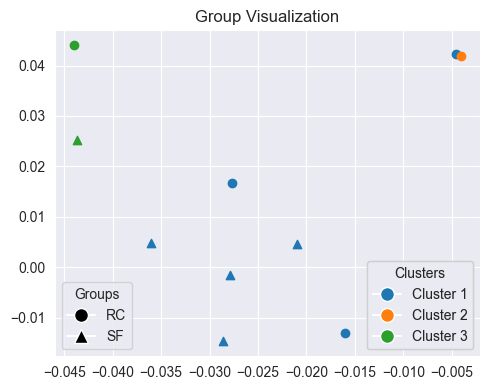

In [554]:
fig, ax = plt.subplots(figsize=(5, 4))
ax = cluster_visualization(X, group_labels, center, cluster_labels, ax)
plt.savefig('cluster_v1.png')
plt.show()

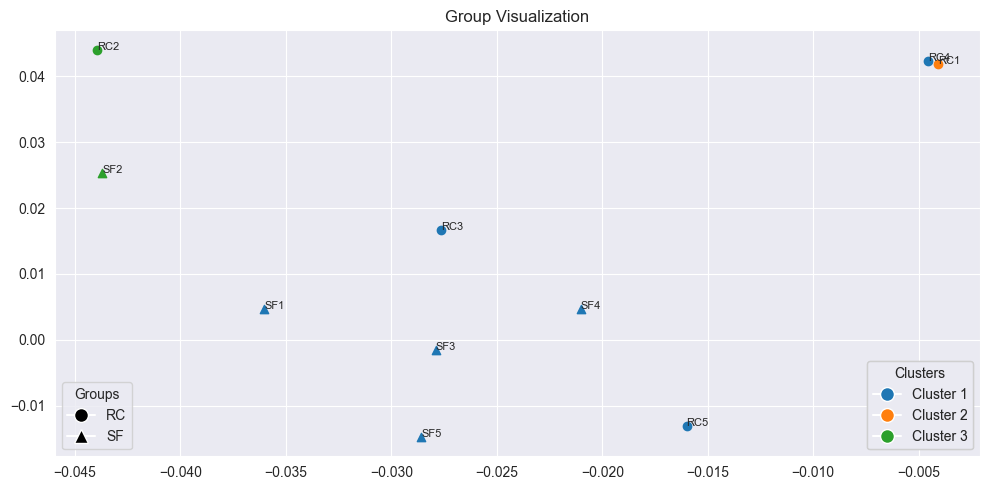

In [552]:
fig, ax = plt.subplots(figsize=(10, 5))
ax = cluster_text_visualization(X, group_labels, center, cluster_labels, annotations, ax)
plt.savefig('cluster_text_v1.png')
plt.show()

## Single variable name clustering 


In [555]:
df_cld = pd.DataFrame()
# create column of dataset, each cell is the keys from my_data dictionary
df_cld['dataset'] = pd.Series(list(my_data.keys()))
df_cld['vars'] = df_cld['dataset'].apply(lambda x: list(my_data[x][0].values()))

df_cld.head(3)

,dataset,vars
0,SF3,"[Stimulant Use, Fatal Overdose, have to use mo..."
1,RC4,"[fatal overdose, stimulant use, fent in the me..."
2,SF2,"[Stimulant Use, Fatal Overdose, Introduction o..."


In [556]:
# Get embeddings of each variable in each text 

# Extract variable names and store them in a dictionary with paragraph indices
global_variable_dict = {}
def get_single_var_dictionary(text, index):
    variable_dict = {}
    for variables in text:
        var_names = [var.strip() for var in variables.split(',')]
        for var in var_names:
            variable_dict[var] = index
    return variable_dict

for i, text in zip(df_cld['dataset'],df_cld['vars']):
    variable_dict = get_single_var_dictionary(text, i)
    global_variable_dict.update(variable_dict)

In [557]:
# Print the first 5 rows of the global_variable_dict
print(list(global_variable_dict.items())[:5])



[('Stimulant Use', 'RC3'), ('Fatal Overdose', 'SF4'), ('have to use more meth for same high', 'SF3'), ('new stuff can feel instantly', 'SF3'), ('will not eat to feel it more', 'SF3')]


In [588]:
# append glo bal_variable_dict keys to a list 
var_list = list(global_variable_dict.keys())
var_embeddings = get_embeddings(var_list)
X =  torch.as_tensor(var_embeddings)

label, center = detect_clusters(X, 3)
# Create a dataframe to store the cluster labels
df_var_cluster = pd.DataFrame({'cluster': label, 'cluster_label': list(global_variable_dict.values()), 'cld variable': list(global_variable_dict.keys())})# print the cluster dataframe
df_var_cluster['group'] = np.where(df_var_cluster['cluster_label'].str.contains('RC', case=False), 'RC', 'SF')
print(df_var_cluster.head(5))

running k-means on cpu..


[running kmeans]: 8it [00:00, 339.40it/s, center_shift=0.000000, iteration=8, tol=0.000001]

   cluster cluster_label                         cld variable group
0        1           RC3                        Stimulant Use    RC
1        1           SF4                       Fatal Overdose    SF
2        1           SF3  have to use more meth for same high    SF
3        0           SF3         new stuff can feel instantly    SF
4        0           SF3         will not eat to feel it more    SF


In [566]:
df_var_cluster

469

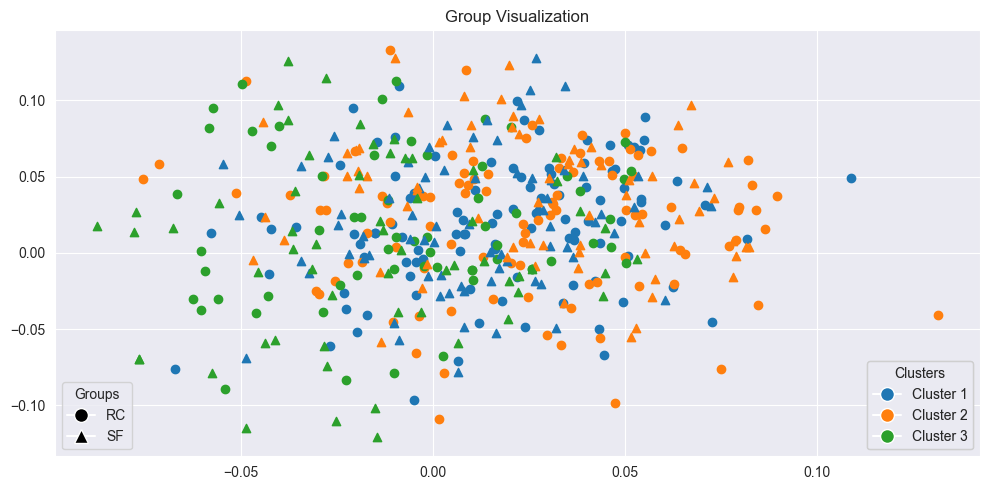

In [561]:
group_labels = np.array(df_var_cluster['group'])
cluster_labels = np.array(df_var_cluster['cluster'])


fig, ax = plt.subplots(figsize=(10, 5))
ax = cluster_visualization(X, group_labels, center, cluster_labels, ax)
plt.savefig('cluster_v2.png')
plt.show()

# 
# fig1, ax = cluster_visualization(X, group_labels, center, cluster_labels)
# plt.savefig('variable_cluster_v2.png')
# plt.show()


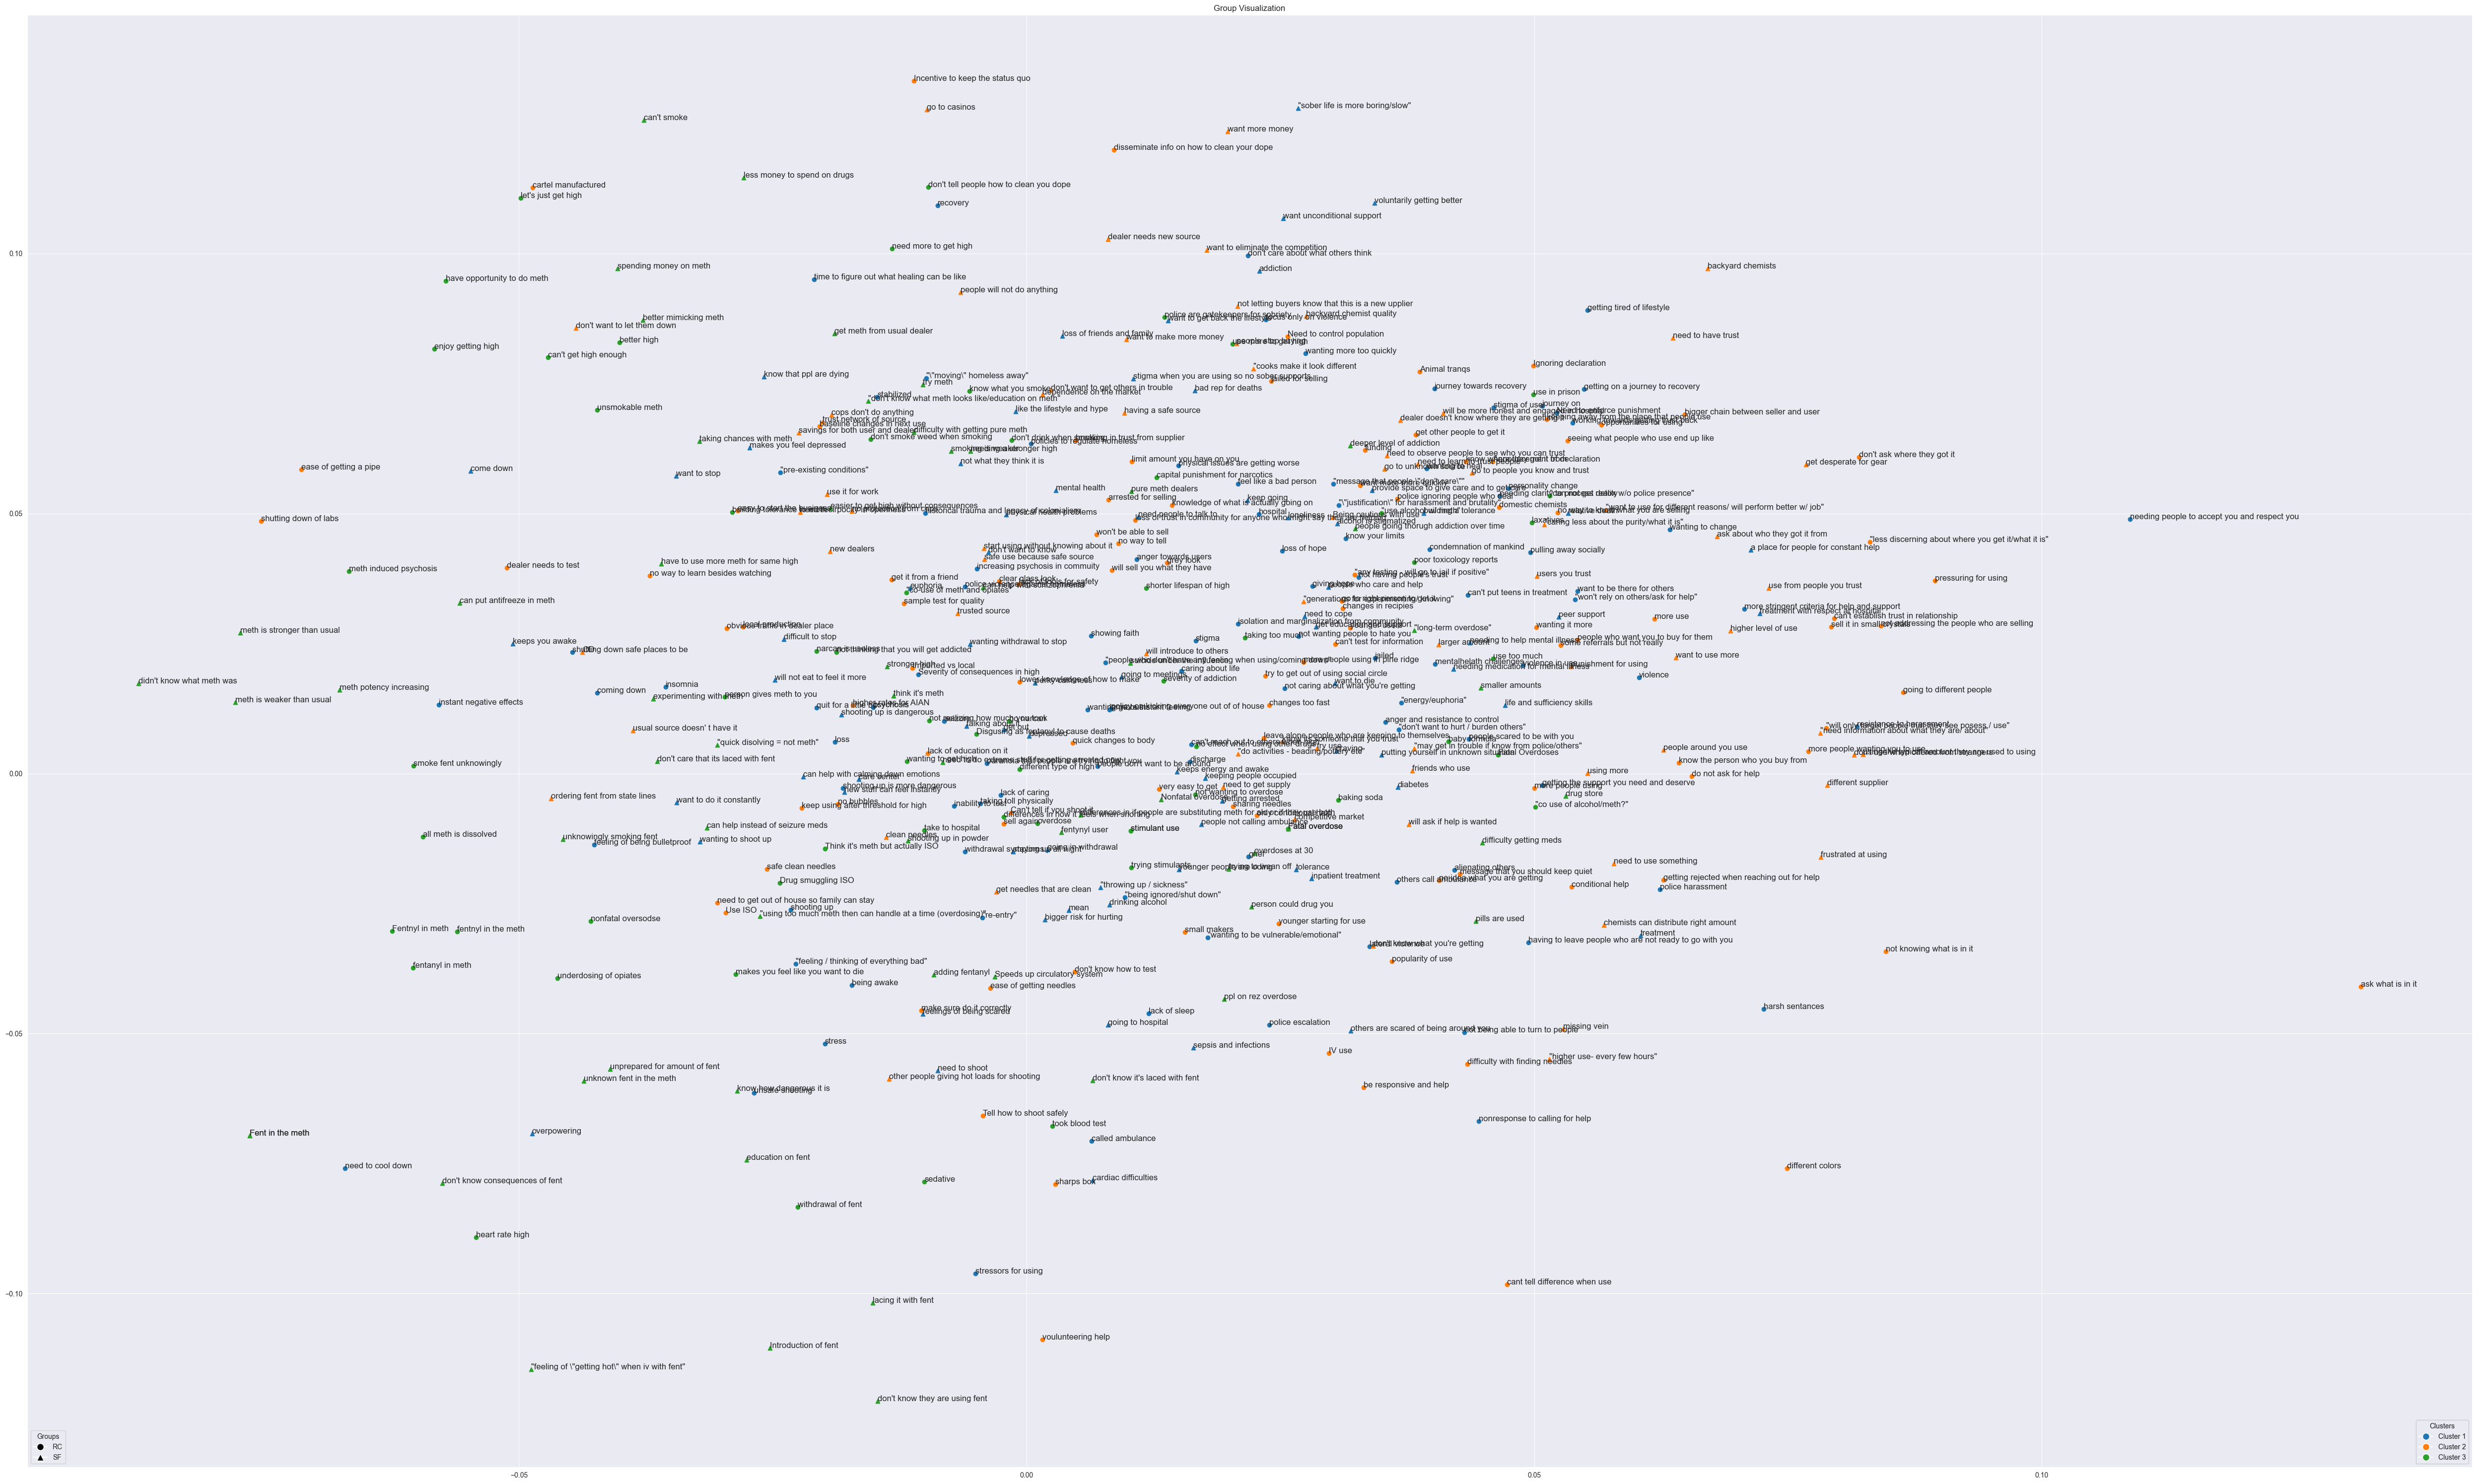

In [565]:
annotations = {float(x): name for x, name in zip(X[:, 0], df_var_cluster['cld variable'])}

# plt.figure(figsize=(50, 20)) 
# plt.rcParams['figure.figsize'] = [20, 50]  # Width=10 inches, Height=5 inches
# plt.figure(figsize=(50, 25))
# 
# fig2, ax = cluster_text_visualization(X, group_labels, center, cluster_labels, annotations)
# # save the plot

fig, ax = plt.subplots(figsize=(50, 30))
ax = cluster_text_visualization(X, group_labels, center, cluster_labels, annotations, ax)
plt.savefig('cluster_text_v2.png')

plt.show()

In [589]:
df_var_cluster
# download as csv 
df_var_cluster.to_csv('df_var_cluster.csv', index=False)

In [584]:


# subste when cluster label is 1 
df_var_cluster.loc[df_var_cluster['cluster'] == 2, ] 

,cluster,cluster_label,cld variable,group
6,2,SF3,"""want to use for different reasons/ will perfo...",SF
9,2,SF3,don't know what you're getting,SF
10,2,SF3,using the typical amount they are used to using,SF
12,2,SF3,get desperate for gear,SF
13,2,SF3,"""cooks make it look different",SF
...,...,...,...,...
462,2,RC3,sell it in small crystals,RC
463,2,RC3,some referrals but not really,RC
464,2,RC3,won't be able to sell,RC
467,2,RC3,get other people to get it,RC


In [586]:
df_var_cluster.loc[df_var_cluster['cluster'] == 1, ] 

,cluster,cluster_label,cld variable,group
3,1,SF3,new stuff can feel instantly,Cluster 1
4,1,SF3,will not eat to feel it more,Cluster 1
8,1,SF3,building a tolerance,Cluster 1
31,1,RC4,getting tired of lifestyle,Cluster 1
33,1,RC3,recovery,Cluster 1
...,...,...,...,...
452,1,RC3,grief,Cluster 1
453,1,RC3,loss,Cluster 1
454,1,RC3,want to be there for others,Cluster 1
455,1,RC3,increasing psychosis in commuity,Cluster 1


In [585]:
df_var_cluster.loc[df_var_cluster['cluster'] == 0, ] 

,cluster,cluster_label,cld variable,group
0,0,RC3,Stimulant Use,RC
1,0,SF4,Fatal Overdose,SF
2,0,SF3,have to use more meth for same high,SF
5,0,SF5,stronger high,SF
7,0,SF3,Speeds up circulatory system,SF
...,...,...,...,...
442,0,RC3,makes you feel like you want to die,RC
444,0,RC3,fentanyl in meth,RC
446,0,RC3,took blood test,RC
461,0,RC3,all meth is dissolved,RC


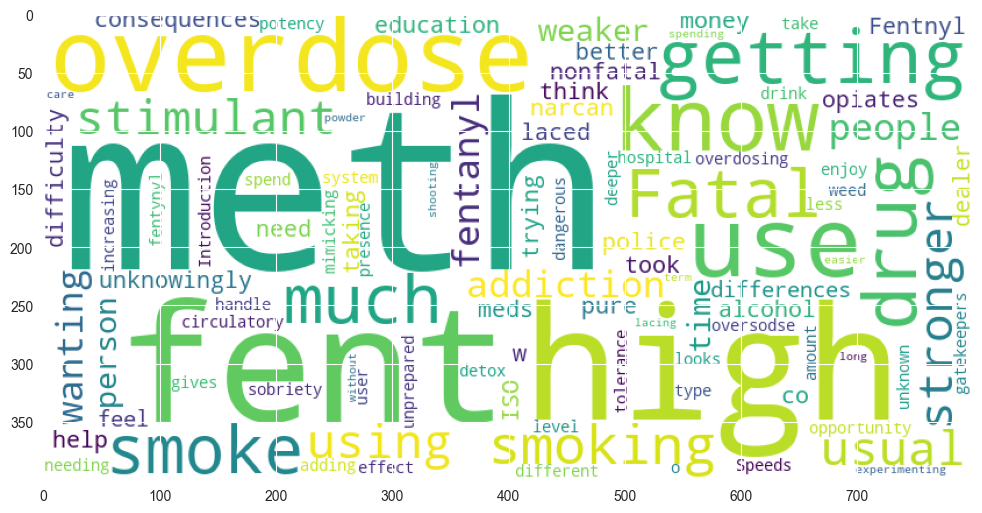

In [582]:
# df_var_cluster.loc[df_var_cluster['cluster'] == 0, ] 
# print these words in a word cloud 
from wordcloud import WordCloud
import matplotlib.pyplot as plt
# Get the variable names in cluster 0
cluster_0_vars = df_var_cluster.loc[df_var_cluster['cluster'] == 0, 'cld variable']
# Create a WordCloud for the variables in cluster 0
wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(' '.join(cluster_0_vars))
plt.figure(figsize=(12, 8))
plt.imshow(wordcloud)


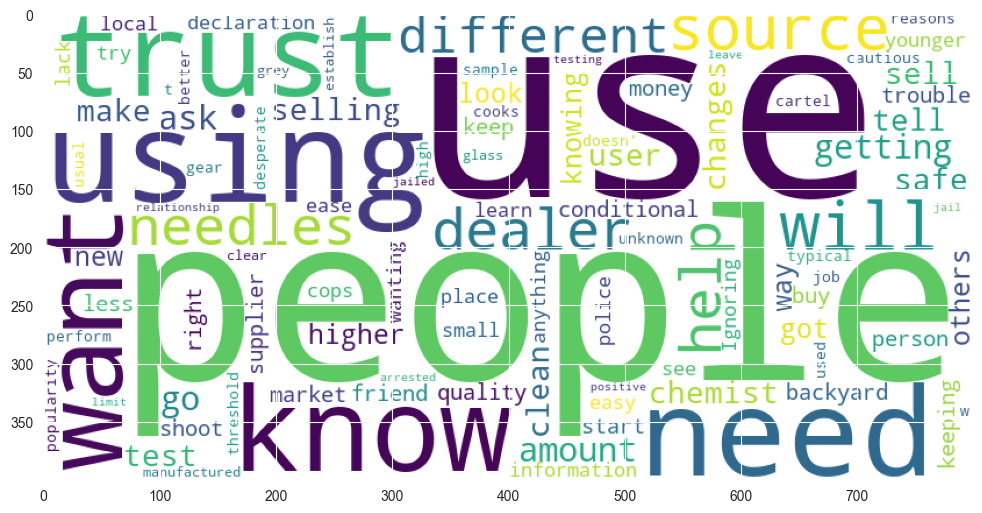

In [580]:
df_var_cluster.loc[df_var_cluster['cluster'] == 2, ] 
cluster_0_vars = df_var_cluster.loc[df_var_cluster['cluster'] == 2, 'cld variable']
# Create a WordCloud for the variables in cluster 0
wordcloud = WordCloud(width=800, height=400, background_color='white',  max_words=100).generate(' '.join(cluster_0_vars))
plt.figure(figsize=(12, 8))
plt.imshow(wordcloud)

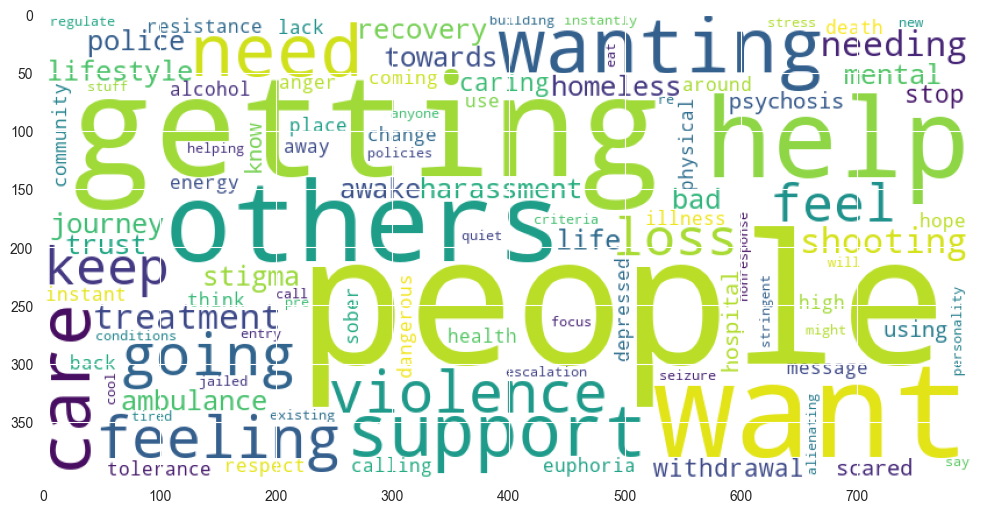

In [583]:
cluster_0_vars = df_var_cluster.loc[df_var_cluster['cluster'] == 1, 'cld variable']
# Create a WordCloud for the variables in cluster 0
wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(' '.join(cluster_0_vars))
plt.figure(figsize=(12, 8))
plt.imshow(wordcloud)

# IGNORE

# Cosine Similarity 

Using Cosine Simil arity to calculate the similarity between the embeddings of the variables in the datasets. 
The result shows that most datasets have some similarity, indicating that there may be some overlap in the variables used across the datasets.



In [ ]:
similarity_matrix = pd.DataFrame(index=df_cld.index, columns=df_cld.index)

for i in range(0, len(my_data)): 
    for j in range(0, len(my_data)):
        if i != j:
            embedding1 = df_cld['embeddings'].iloc[i].unsqueeze(0)
            embedding2 = df_cld['embeddings'].iloc[j].unsqueeze(0)
            
            similarity_score = torch.nn.functional.cosine_similarity(embedding1, embedding2)
            # store the score in the similarity matrix
            similarity_matrix.loc[i, j] = similarity_score.item()

similarity_matrix.columns = df_cld['dataset']
similarity_matrix.index = df_cld['dataset']
similarity_matrix

In [ ]:
similarity_matrix = similarity_matrix.astype(float)
sns.heatmap(similarity_matrix, annot=True)

In [ ]:
# df_cld['cld_vars'] = df_cld['vars'].apply(listToString)

In [ ]:
# create_heatmap(cosine_similarity(arr))

# Using pre-trained sentence transformer to compute text similarity

Sentence transformer models captures semantic information in text and can be used to compute text similarity. Here, we use the 'universal-sentence-encoder' model to compute the similarity between the variables in the datasets.

In [ ]:
from absl import logging
import tensorflow as tf
import tensorflow_hub as hub

module_url = "https://tfhub.dev/google/universal-sentence-encoder/4"
model = hub.load(module_url)
print ("module %s loaded" % module_url)
def embed(input):
  return model(input)


In [ ]:
message_embeddings_ = embed(string_list)

corr = np.inner(message_embeddings_, message_embeddings_)

In [ ]:
create_heatmap(corr)

In [ ]:
df_cluster

In [ ]:
fig, ax = plt.subplots()
ax.scatter(X[:,0], X[:,1])
colors = ['r', 'g']
plt.title("Cluster of OverCome")
for i, txt in enumerate(df_cluster['label']):
    ax.annotate(txt, (X[i,0], X[i,1]))
    # get different color based on cluster label in df_cluster
    color = colors[df_cluster['cluster'][i]]
    
    ax.scatter(X[i,0], X[i,1], c=color)

In [ ]:

# from sklearn.feature_extraction.text import CountVectorizer
# vectorizer = CountVectorizer()
# vectorizer.fit(list(df_cld['cld_vars']))
# print(vectorizer.vocabulary_)